# 17. Luật chọn neo theo ngưỡng độ phủ

Sổ tay notebook 11 cho thấy sáu kênh không hưởng lợi từ neo B mà còn xấu đi nhẹ, gồm NIMAP, NIDiasABP, NISysABP, Cholesterol, RespRate và MAP. Điểm chung của chúng là độ phủ cao hoặc tỷ lệ trùng neo cao, tức là hai neo gần như đồng nhất và phần chênh còn lại là nhiễu. Điều đó gợi một giả thuyết thiết kế: neo nên được chọn theo kênh thay vì áp dụng đồng nhất cho cả ba mươi bảy kênh.

Câu hỏi cụ thể: một luật cứng, dùng neo B cho kênh thưa và neo A cho kênh dày, có thu thêm được phần hiệu ứng nào so với neo B thuần hay không.

Ràng buộc phương pháp luận quan trọng nhất của sổ tay này: ngưỡng độ phủ phải được xác định trên tập huấn luyện. Nếu chọn ngưỡng theo kết quả của tập kiểm tra thì đó là rò rỉ thông tin và mọi con số thu được đều mất giá trị. Vì vậy danh sách kênh dùng neo B được chốt trước khi huấn luyện, chỉ dựa trên độ phủ của tập huấn luyện.

Đối chiếu với tuần 2: cổng học được theo kênh ở neo D cho 0,442668, kém hơn neo B thuần ở 0,436195. Như vậy việc cho mô hình tự học mức độ tin vào neo đã thất bại một lần. Giả thuyết luật cứng vì thế không hiển nhiên thắng, và đó chính là lý do đáng thử: kết quả âm tính cũng có giá trị vì nó khẳng định neo B thuần đã đủ tốt.

Chi phí ước lượng khoảng mười phút cho ba hạt giống.

> **Vị trí trong chuỗi tái lập:** notebook 17 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 11-Chi_so_theo_nhom_kenh.
>
> **Thư mục kết quả:** `Output/processed/w3_24_neo_theo_nguong_do_phu/`.
>
> **Mã định danh nội bộ:** `W3_24`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_24_neo_theo_nguong_do_phu"  #@param {type:"string"}
NGUONG_PHU_DUNG_NEO_B = 0.50  #@param {type:"number"}
NGUON_NEO_AB = "w3_18_chi_so_theo_nhom_kenh"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_24_neo_theo_nguong_do_phu
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:37:06
run_tag      w3_24_neo_theo_nguong_do_phu
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm dùng chung

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Mot ham du bao duy nhat cho moi phep phan tich chi tiet.
def du_bao_tap_kiem_tra(model):
    model.eval()
    phan = []
    with torch.no_grad():
        for x, mxx, y, myy in DataLoader(SPLITS["test"], batch_size=BATCH, shuffle=False):
            phan.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    return np.concatenate(phan).astype(np.float64)


Y_TEST = SPLITS["test"].tensors[2].numpy().astype(np.float64)
M_TEST = SPLITS["test"].tensors[3].numpy().astype(np.float64)
X_TEST = SPLITS["test"].tensors[0].numpy().astype(np.float64)
MX_TEST = SPLITS["test"].tensors[1].numpy().astype(np.float64)
print("Tập kiểm tra:", Y_TEST.shape[0], "hồ sơ |", int(M_TEST.sum()), "điểm quan sát thật")


Tập kiểm tra: 1585 hồ sơ | 136752 điểm quan sát thật


## 3. Chốt danh sách kênh dùng neo B trên tập huấn luyện

Độ phủ được đo trên cửa sổ đầu vào của tập huấn luyện, đúng phần thông tin mà neo nhìn thấy. Độ phủ của tập kiểm tra cũng được in ra nhưng chỉ để đối chiếu, không tham gia vào việc chọn ngưỡng.

In [10]:
MX_TRAIN = SPLITS["train"].tensors[1].numpy().astype(np.float64)
DO_PHU_TRAIN = MX_TRAIN.mean(axis=(0, 1))
DO_PHU_TEST = MX_TEST.mean(axis=(0, 1))

DUNG_NEO_B = DO_PHU_TRAIN < NGUONG_PHU_DUNG_NEO_B
print("Số kênh dùng neo B:", int(DUNG_NEO_B.sum()), "| số kênh dùng neo A:",
      int((~DUNG_NEO_B).sum()))
print("Kênh dùng neo A, tức kênh dày phép đo:")
for i in range(N_CH):
    if not DUNG_NEO_B[i]:
        print("   ", str(channels[i]).ljust(14),
              "độ phủ huấn luyện", round(float(DO_PHU_TRAIN[i]), 4),
              "| độ phủ kiểm tra", round(float(DO_PHU_TEST[i]), 4))

MAT_NA_NEO_B = torch.from_numpy(DUNG_NEO_B.astype(np.float32)).to(DEVICE)
print("Đã chốt mặt nạ chọn neo trên tập huấn luyện")


Số kênh dùng neo B: 31 | số kênh dùng neo A: 6
Kênh dùng neo A, tức kênh dày phép đo:
    DiasABP        độ phủ huấn luyện 0.5413 | độ phủ kiểm tra 0.5576
    HR             độ phủ huấn luyện 0.9033 | độ phủ kiểm tra 0.914
    MAP            độ phủ huấn luyện 0.5378 | độ phủ kiểm tra 0.5553
    SysABP         độ phủ huấn luyện 0.5414 | độ phủ kiểm tra 0.5577
    Urine          độ phủ huấn luyện 0.6966 | độ phủ kiểm tra 0.7074
    Weight         độ phủ huấn luyện 0.5094 | độ phủ kiểm tra 0.5156
Đã chốt mặt nạ chọn neo trên tập huấn luyện


## 4. Lớp mô hình neo lai

Lớp dưới đây kế thừa nguyên lớp mô hình chung và chỉ ghi đè đúng một hàm tính neo, nên mọi phần còn lại gồm kiến trúc tuyến tính, kênh mặt nạ và cách gộp lại neo ở đầu ra đều giỵ nguyên. Hàm huấn luyện chung tạo mô hình qua tên `LinearFamily`, nên lớp mới được gắn vào tên đó trong lúc chạy rồi trả lại ngay sau khi xong, để không phải sao chép thêm một bản vòng lặp huấn luyện thứ hai.

In [11]:
LinearFamily_goc = LinearFamily


class LinearNeoLai(LinearFamily_goc):
    # Neo lai: kênh có mặt nạ bằng một dùng quan sát thật gần nhất, tức neo B;
    # Kênh còn lại dùng bước cuối của cửa sổ, tức neo A.
    def compute_anchor(self, x, mask):
        val_b, _ = last_observed(x, mask)
        val_a = x[:, -1, :]
        na = MAT_NA_NEO_B.view(1, -1).to(x.device)
        return na * val_b + (1.0 - na) * val_a


def chay_neo_lai(seed, nhan):
    global LinearFamily
    LinearFamily = LinearNeoLai
    try:
        return chay_mot_cau_hinh("nlinear", anchor="B", seed=seed, nhan=nhan)
    finally:
        LinearFamily = LinearFamily_goc


# Phép tự kiểm tra định nghĩa: nếu mặt nạ toàn một thì neo lai phải trùng neo B,
# Nếu mặt nạ toàn không thì phải trùng neo A.
x_thu = SPLITS["test"].tensors[0][:64].to(DEVICE)
m_thu = SPLITS["test"].tensors[1][:64].to(DEVICE)
mo_hinh_thu = LinearNeoLai(SEQ_LEN, PRED_LEN, N_CH, kind="nlinear", anchor="B").to(DEVICE)
neo_B_that, _ = last_observed(x_thu, m_thu)
neo_A_that = x_thu[:, -1, :]
MAT_NA_GOC = MAT_NA_NEO_B.clone()
MAT_NA_NEO_B = torch.ones_like(MAT_NA_GOC)
lech_b = float((mo_hinh_thu.compute_anchor(x_thu, m_thu) - neo_B_that).abs().max())
MAT_NA_NEO_B = torch.zeros_like(MAT_NA_GOC)
lech_a = float((mo_hinh_thu.compute_anchor(x_thu, m_thu) - neo_A_that).abs().max())
MAT_NA_NEO_B = MAT_NA_GOC
print("Sai lệch khi mặt nạ toàn một:", lech_b, "| khi mặt nạ toàn không:", lech_a)
assert lech_b < 1e-6 and lech_a < 1e-6, "Định nghĩa neo lai không đúng ở hai trường hợp biên"


Sai lệch khi mặt nạ toàn một: 0.0 | khi mặt nạ toàn không: 0.0


## 5. Huấn luyện neo lai và đọc lại hai neo thuần

Neo lai được huấn luyện với đúng số hạt giống và đúng mọi siêu tham số của hai neo thuần. Hai neo thuần được đọc lại từ notebook 11 để không chạy trùng, và chỉ số đọc lại được in ra để đối chiếu với bảng tuần 2.

In [12]:
SEEDS = list(range(N_SEEDS))
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

TEN_LAI = []
for s in SEEDS:
    ten = "nlinear_neolai_mse_s" + str(s)
    chay_neo_lai(s, ten)
    TEN_LAI.append(ten)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
nlinear_neolai_mse_s0            MSE_obs 0.4413 | MAE_obs 0.4396 | 12 giây | 876 tham số
nlinear_neolai_mse_s1            MSE_obs 0.4415 | MAE_obs 0.4393 | 7 giây | 876 tham số
nlinear_neolai_mse_s2            MSE_obs 0.4415 | MAE_obs 0.4398 | 7 giây | 876 tham số
Tổng thời gian: 0.5 phút


In [13]:
se_lai, ae_lai, dem_lai = nap_tong_tu_danh_sach(
    [RUNS / (t + "_patient_sums.npz") for t in TEN_LAI])

THUAN = {}
for neo in ("A", "B"):
    tep = [OUT / "processed" / NGUON_NEO_AB / "runs" /
           ("nlinear_neo" + neo + "_mse_s" + str(s) + "_patient_sums.npz") for s in SEEDS]
    if all(t.exists() for t in tep):
        se, ae, dem = nap_tong_tu_danh_sach(tep)
        nguon = NGUON_NEO_AB
    else:
        print("Không thấy kết quả cũ của neo", neo, "nên huấn luyện bù")
        for s in SEEDS:
            chay_mot_cau_hinh("nlinear", anchor=neo, seed=s,
                              nhan="nlinear_neo" + neo + "_mse_s" + str(s))
        se, ae, dem = nap_tong_tu_danh_sach(
            [RUNS / ("nlinear_neo" + neo + "_mse_s" + str(s) + "_patient_sums.npz")
             for s in SEEDS])
        nguon = RUN_TAG
    THUAN[neo] = {"se": se, "ae": ae, "dem": dem, "nguon": nguon,
                  "mse": float(se.sum() / (dem.sum() + EPS)),
                  "mae": float(ae.sum() / (dem.sum() + EPS))}
    print("Neo", neo, "| MSE", round(THUAN[neo]["mse"], 6),
          "| MAE", round(THUAN[neo]["mae"], 6), "| nguồn", nguon)

mse_lai = float(se_lai.sum() / (dem_lai.sum() + EPS))
mae_lai = float(ae_lai.sum() / (dem_lai.sum() + EPS))
print("Neo lai | MSE", round(mse_lai, 6), "| MAE", round(mae_lai, 6))


Neo A | MSE 0.488031 | MAE 0.471698 | nguồn w3_18_chi_so_theo_nhom_kenh
Neo B | MSE 0.436036 | MAE 0.437276 | nguồn w3_18_chi_so_theo_nhom_kenh
Neo lai | MSE 0.441425 | MAE 0.439594


## 6. Kiểm định bắt cặp

Hai hiệu được kiểm định. Hiệu thứ nhất so neo lai với neo B thuần và trả lời đúng câu hỏi của sổ tay. Hiệu thứ hai so neo lai với neo A thuần để biết luật cứng có giữ được phần lợi ích chính hay không.

In [14]:
KIEM_DINH = {}
for neo in ("B", "A"):
    kq = hieu_so_bat_cap(se_lai, ae_lai, THUAN[neo]["se"], THUAN[neo]["ae"],
                         dem_lai, n_boot=N_BOOT, seed=0)
    KIEM_DINH["lai_tru_neo" + neo] = {k: v for k, v in kq.items()
                                      if not k.startswith("mau_bootstrap")}
    print(("Neo lai trừ neo " + neo).ljust(22), "hiệu MSE", round(kq["hieu_mse"], 6),
          kq["hieu_mse_ci"], "p", round(kq["p_hai_phia_mse"], 4))

h = KIEM_DINH["lai_tru_neoB"]
if h["hieu_mse"] < 0 and h["p_hai_phia_mse"] < 0.05:
    KET_LUAN = "Luật chọn neo theo kênh thu thêm được lợi ích so với neo B thuần"
elif h["p_hai_phia_mse"] >= 0.05:
    KET_LUAN = "Luật chọn neo theo kênh không khác biệt so với neo B thuần"
else:
    KET_LUAN = "Luật chọn neo theo kênh kém hơn neo B thuần"
print("Kết luận:", KET_LUAN)


Neo lai trừ neo B      hiệu MSE 0.005389 [0.0026931566344359165, 0.0085433787606805] p 0.0
Neo lai trừ neo A      hiệu MSE -0.046606 [-0.0539364046135594, -0.039169799548131226] p 0.0
Kết luận: Luật chọn neo theo kênh kém hơn neo B thuần


## 7. Hình so sánh ba cách neo

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_24_neo_theo_nguong_do_phu/figures/W3_24_neo_theo_nguong_do_phu.png


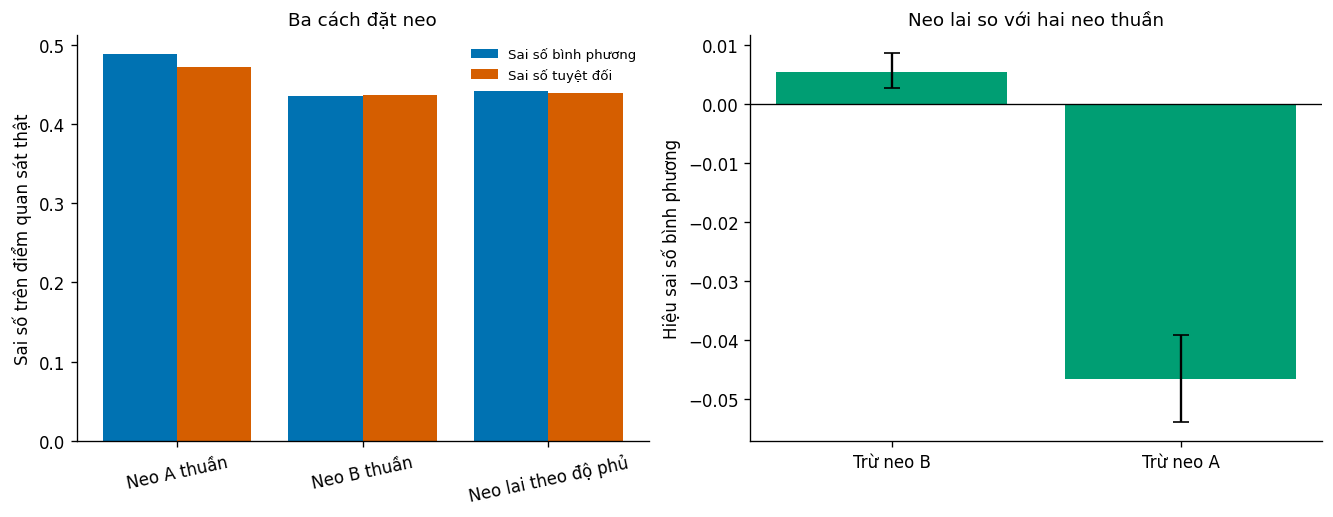

In [15]:
nhan = ["Neo A thuần", "Neo B thuần", "Neo lai theo độ phủ"]
mse_ba = [THUAN["A"]["mse"], THUAN["B"]["mse"], mse_lai]
mae_ba = [THUAN["A"]["mae"], THUAN["B"]["mae"], mae_lai]
vi_tri = np.arange(3)

fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.2))
ax[0].bar(vi_tri - 0.2, mse_ba, width=0.4, label="Sai số bình phương", color=PALETTE[0])
ax[0].bar(vi_tri + 0.2, mae_ba, width=0.4, label="Sai số tuyệt đối", color=PALETTE[1])
ax[0].set_xticks(vi_tri)
ax[0].set_xticklabels(nhan, rotation=12)
ax[0].set_ylabel("Sai số trên điểm quan sát thật")
ax[0].set_title("Ba cách đặt neo")
ax[0].legend(fontsize=8)

khoa = ["lai_tru_neoB", "lai_tru_neoA"]
nhan_hieu = ["Trừ neo B", "Trừ neo A"]
gia = [KIEM_DINH[k]["hieu_mse"] for k in khoa]
ci = [KIEM_DINH[k]["hieu_mse_ci"] for k in khoa]
duoi = [g - x[0] for g, x in zip(gia, ci)]
tren = [x[1] - g for g, x in zip(gia, ci)]
ax[1].bar(nhan_hieu, gia, yerr=[duoi, tren], color=PALETTE[2], capsize=5)
ax[1].axhline(0.0, color="black", linewidth=0.8)
ax[1].set_ylabel("Hiệu sai số bình phương")
ax[1].set_title("Neo lai so với hai neo thuần")
luu_hinh(fig, "W3_24_neo_theo_nguong_do_phu.png")
plt.show()


## 8. Ghi kết quả

In [16]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "n_boot": N_BOOT,
    "nguong_phu_dung_neo_b": NGUONG_PHU_DUNG_NEO_B,
    "chon_nguong_tren": "tap_huan_luyen",
    "so_kenh_dung_neo_b": int(DUNG_NEO_B.sum()),
    "kenh_dung_neo_a": [str(channels[i]) for i in range(N_CH) if not DUNG_NEO_B[i]],
    "do_phu_huan_luyen": [float(v) for v in DO_PHU_TRAIN],
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "mse_neo_lai": mse_lai, "mae_neo_lai": mae_lai,
    "ky_nang_mae_neo_lai": float(1.0 - mae_lai / MAE_PERSISTENCE),
    "chi_so_neo_thuan": {k: {"mse": v["mse"], "mae": v["mae"], "nguon": v["nguon"]}
                         for k, v in THUAN.items()},
    "kiem_dinh": KIEM_DINH,
    "ket_luan": KET_LUAN,
}
dich = RUN_DIR / "W3_neo_theo_nguong_do_phu.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_24_neo_theo_nguong_do_phu/W3_neo_theo_nguong_do_phu.json
